# 02 — Error Accumulation by Forecast Horizon (h = 1..7 Days)

Phân tích độ suy giảm độ chính xác theo bước dự báo h = 1 đến h = 7 trên 4 chỉ số chính thức (MAE@h, MSE@h, RMSE@h, MASE@h).

### Project Guardrails & Execution Baseline:
- **Protocol Căn cứ:** `training_forecasting_evaluation_protocol_v1_0_21.md` và `spec_module_result_analysis_v2.md`
- **Zero Final Test Access Rule:** Chỉ nạp dữ liệu Validation (724 origins, 2018-05-01 đến 2020-04-23, H=7).
- **Purged Metrics Integrity:** Tuyệt đối không tính hoặc hiển thị CR-MAE@7, CR-Bias@7, RainDay-MAE, hay Bias.
- **Descriptive Cost Principle:** Số liệu tài nguyên chỉ dùng mô tả (PROP-07), không dùng để xếp hạng mô hình.


In [1]:
# Bootstrap root directory
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

ROOT_DIR = Path.cwd()
while not (ROOT_DIR / 'src').exists() and ROOT_DIR != ROOT_DIR.parent:
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


Family Champions: ['SC-04', 'SC-37', 'SC-01', 'SC-08', 'SC-13', 'SC-30', 'SC-42']


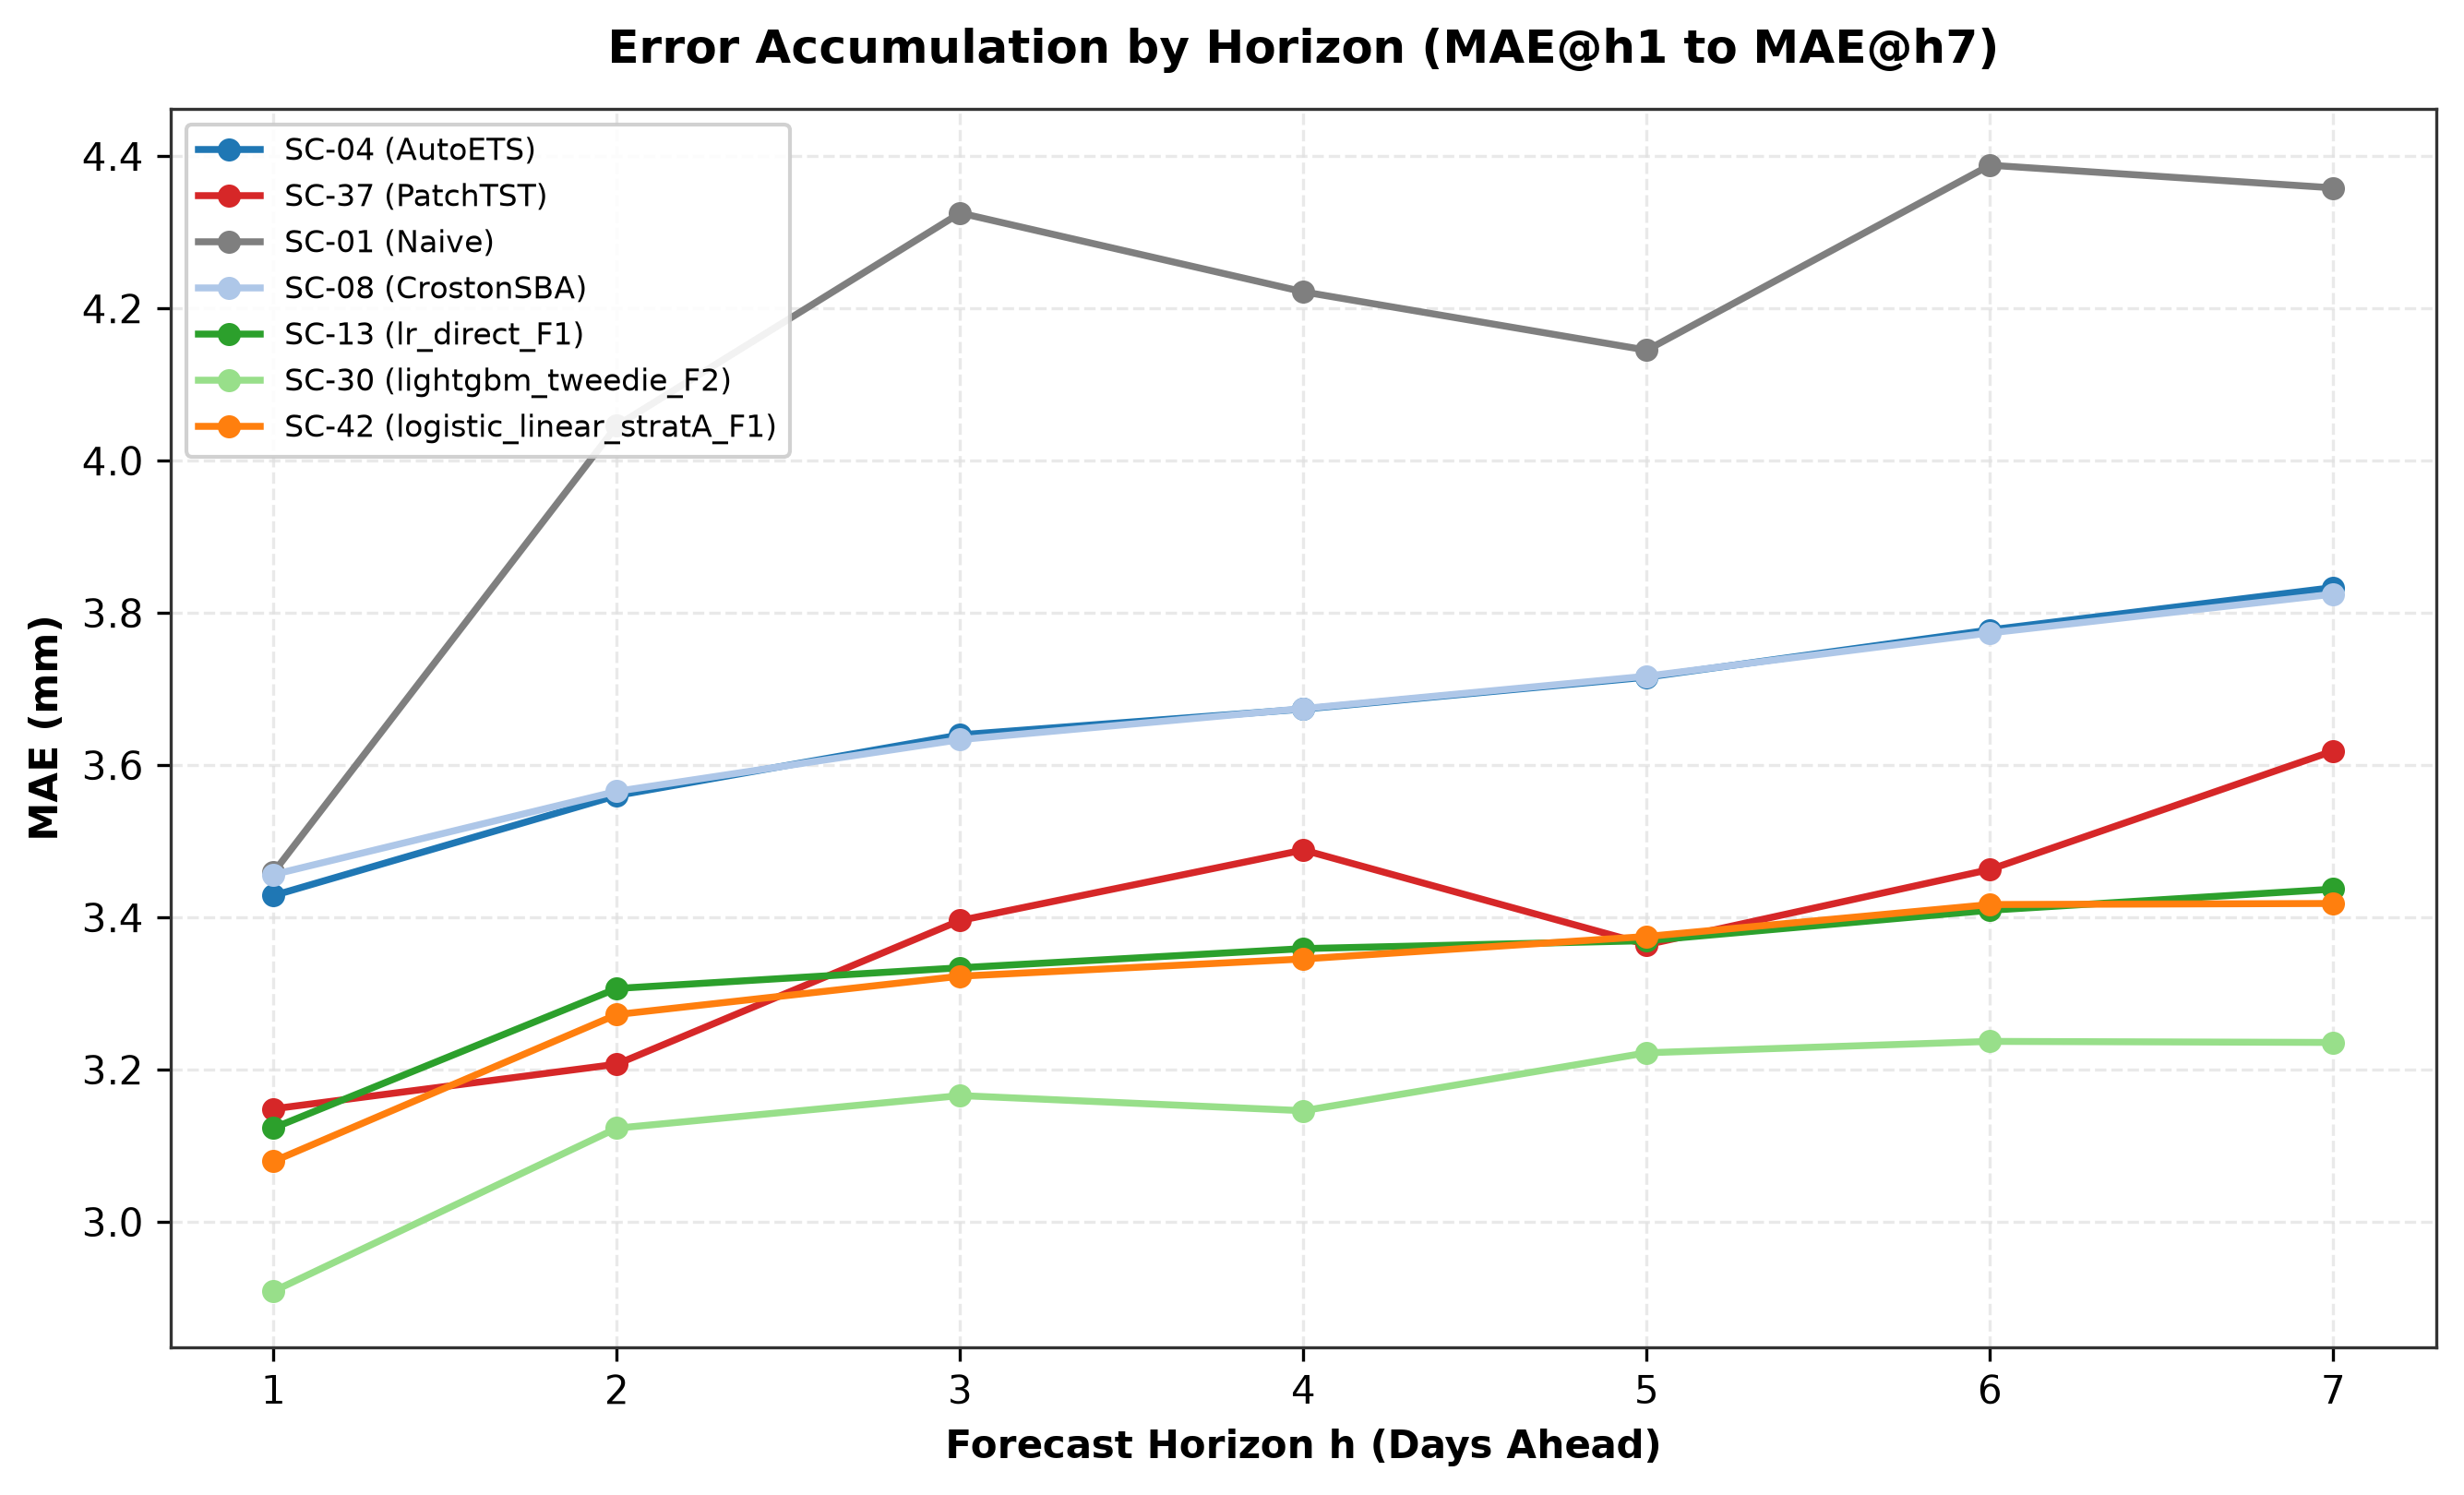

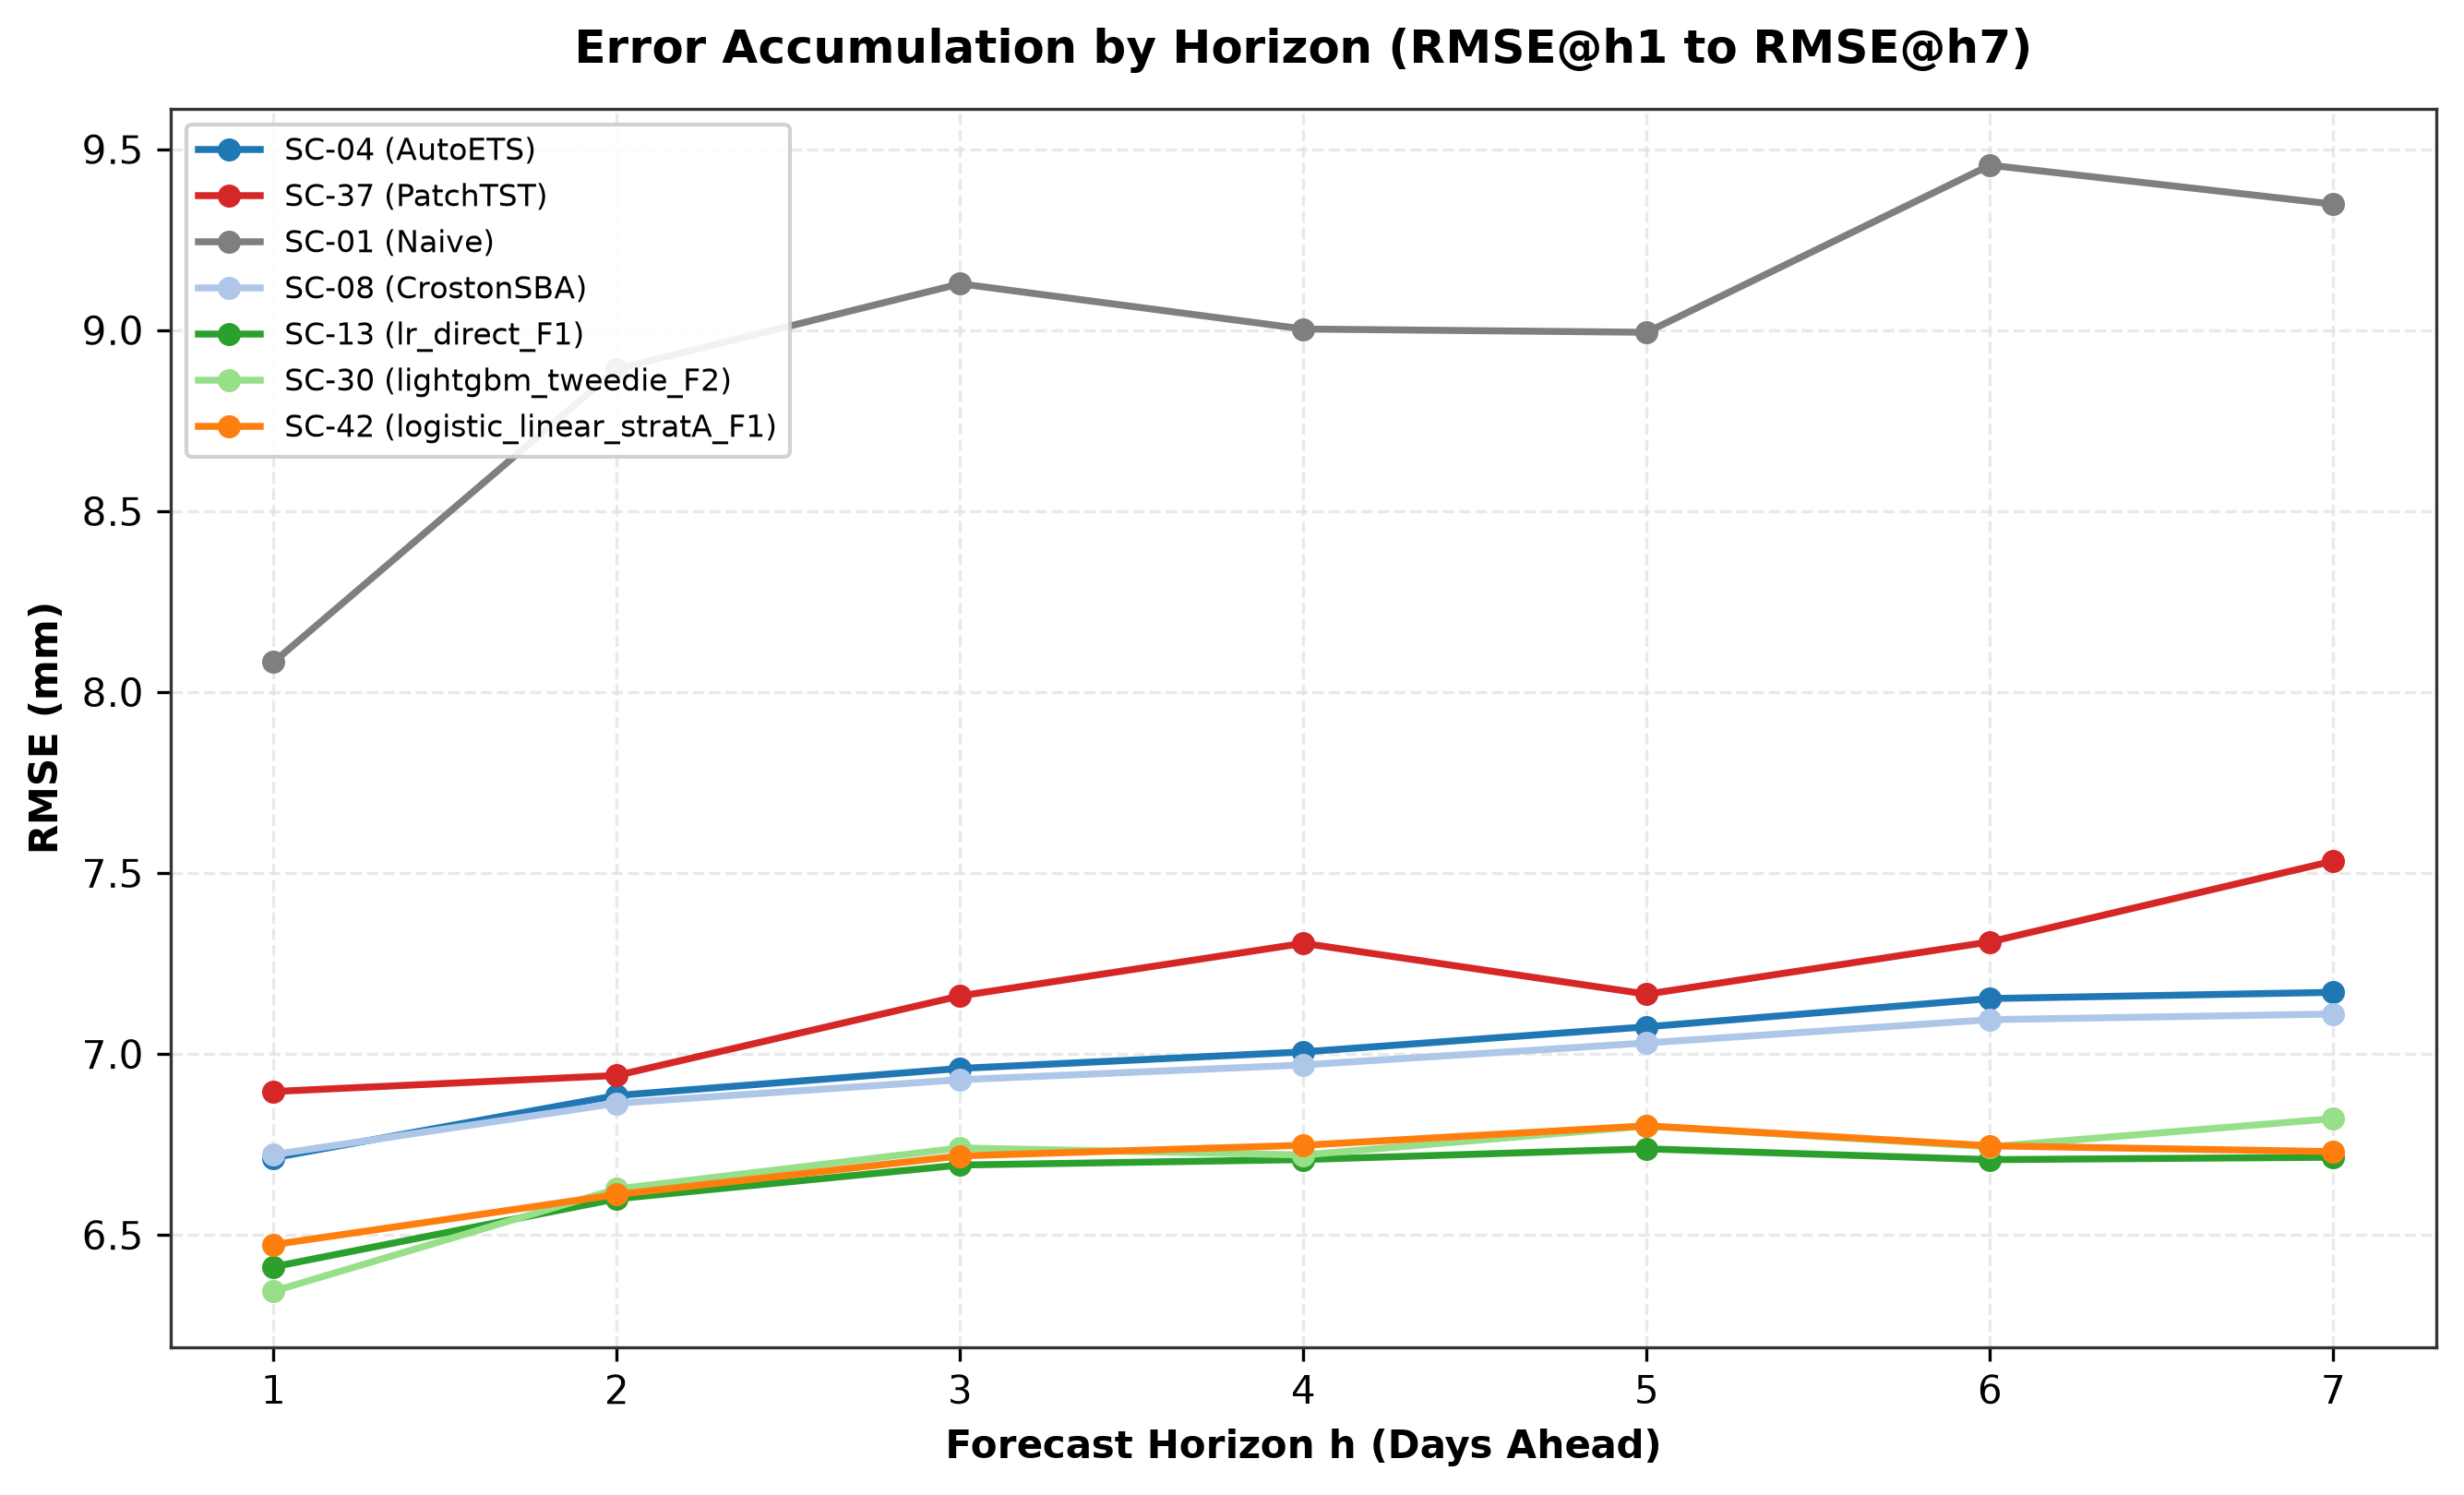

In [2]:
from src.analysis.loaders import load_all_horizon_breakdowns, load_all_validation_results
from src.analysis.ranking import compute_official_leaderboard
from src.analysis.plotting import plot_horizon_metric_curves
import matplotlib.pyplot as plt

df_h = load_all_horizon_breakdowns()
df_ranked = compute_official_leaderboard(load_all_validation_results())

# Select champions from each family
top_scenarios = df_ranked.groupby('family').first()['scenario_id'].tolist()
print(f"Family Champions: {top_scenarios}")

# Plot MAE curves
fig_mae = plot_horizon_metric_curves(df_h, top_scenarios, metric='MAE', save_name='fig02_horizon_mae.png')

# Plot RMSE curves
fig_rmse = plot_horizon_metric_curves(df_h, top_scenarios, metric='RMSE', save_name='fig02_horizon_rmse.png')
